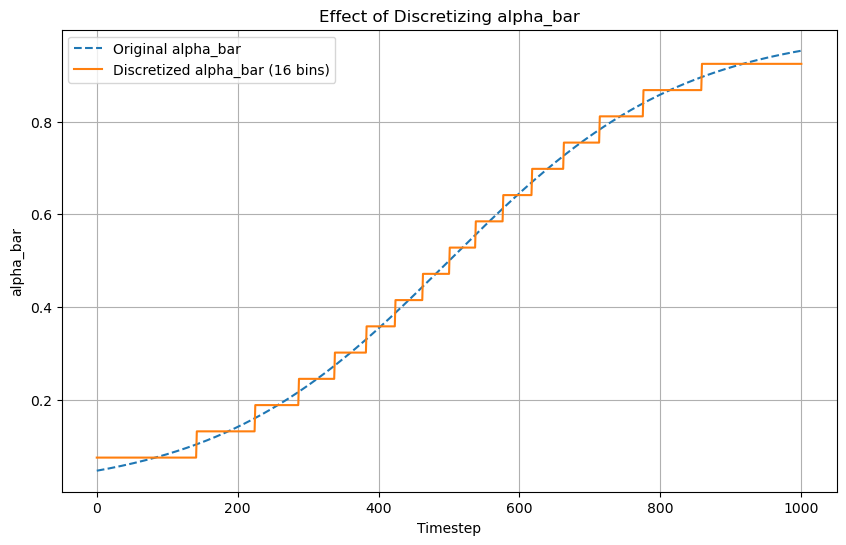

In [24]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

def sigmoid_schedule(t, start=-3, end=3, tau=1.0, clip_min=1e-9, center=0.0):
    # Sigmoid interpolation in log-space
    sigmoid = torch.sigmoid((t - center) * (end - start) / tau + start)
    return torch.clip(sigmoid, clip_min, 1.0)

def discretize_with_bins(values, n_bins):
    min_val = values.min()
    max_val = values.max()
    bins = torch.linspace(min_val, max_val, n_bins + 1)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    indices = torch.bucketize(values, bins) - 1
    indices = torch.clamp(indices, 0, n_bins - 1)
    return bin_centers[indices]

def generate_beta_schedule_discretized_alpha_bar(timesteps, n_bins=16, start=-3, end=3, tau=1.0, clip_min=1e-9, center=0.0):
    t = torch.linspace(0, 1, timesteps + 1)
    
    # Step 1: Generate continuous alpha_bars
    alpha_bars = sigmoid_schedule(t, start=start, end=end, tau=tau, clip_min=clip_min, center=center)

    # Step 2: Discretize alpha_bars (still length T+1)
    alpha_bars_discrete = discretize_with_bins(alpha_bars, n_bins)

    # Step 3: Derive betas from discretized alpha_bars
    betas = 1 - (alpha_bars_discrete[1:] / alpha_bars_discrete[:-1])
    betas = torch.clip(betas, 1e-4, 0.999)  # Stability

    return betas, alpha_bars, alpha_bars_discrete

timesteps = 1000
n_bins = 16
betas, alpha_bars, alpha_bars_discrete = generate_beta_schedule_discretized_alpha_bar(timesteps, n_bins=n_bins)

plt.figure(figsize=(10, 6))
plt.plot(alpha_bars.numpy(), label='Original alpha_bar', linestyle='--')
plt.plot(alpha_bars_discrete.numpy(), label=f'Discretized alpha_bar ({n_bins} bins)', linestyle='-')
plt.xlabel("Timestep")
plt.ylabel("alpha_bar")
plt.title("Effect of Discretizing alpha_bar")
plt.legend()
plt.grid(True)
plt.show()

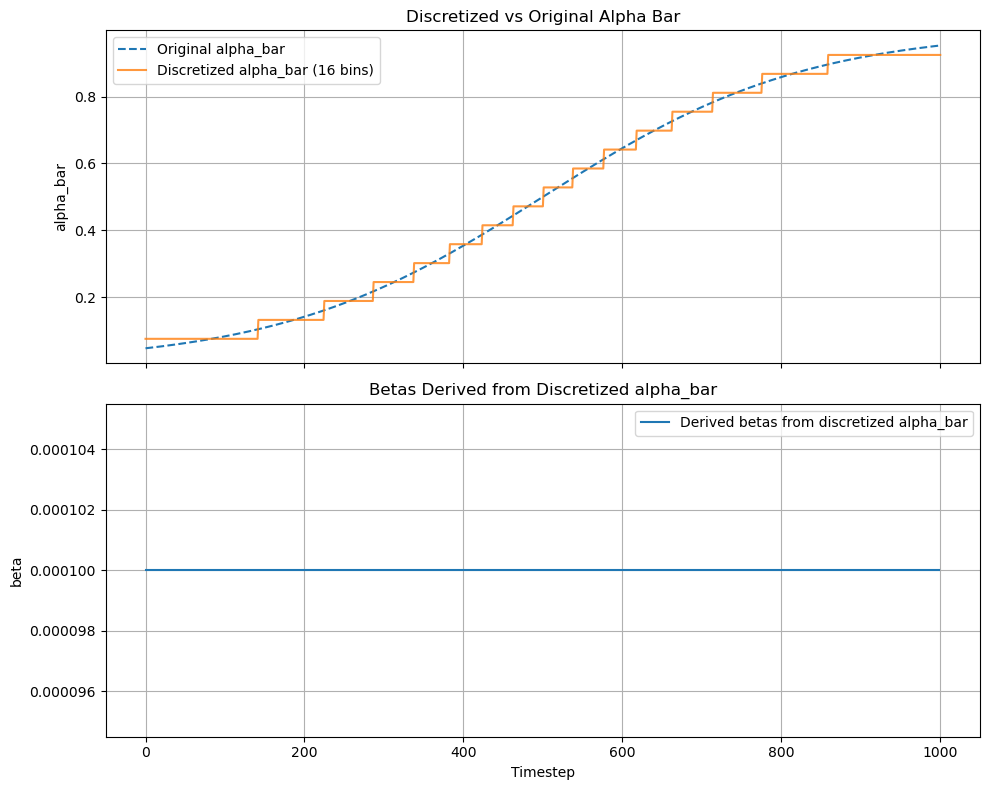

In [25]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 1. Define sigmoid alpha_bar schedule
def sigmoid_schedule(t, start=-3, end=3, tau=1.0, clip_min=1e-9, center=0.0):
    sigmoid = torch.sigmoid((t - center) * (end - start) / tau + start)
    return torch.clip(sigmoid, clip_min, 1.0)

# 2. Binning function
def discretize_with_bins(values, n_bins):
    min_val = values.min()
    max_val = values.max()
    bins = torch.linspace(min_val, max_val, n_bins + 1)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    indices = torch.bucketize(values, bins) - 1
    indices = torch.clamp(indices, 0, n_bins - 1)
    return bin_centers[indices]

# 3. Discretize alpha_bar and derive betas
def generate_beta_schedule_discretized_alpha_bar(timesteps, n_bins=16, start=-3, end=3, tau=1.0, clip_min=1e-9, center=0.0):
    t = torch.linspace(0, 1, timesteps + 1)
    alpha_bars = sigmoid_schedule(t, start=start, end=end, tau=tau, clip_min=clip_min, center=center)
    alpha_bars_discrete = discretize_with_bins(alpha_bars, n_bins)
    betas = 1 - (alpha_bars_discrete[1:] / alpha_bars_discrete[:-1])
    
    betas = torch.clip(betas, 1e-4, 0.999)  # avoid invalid beta values
    return betas, alpha_bars, alpha_bars_discrete

# --- Run ---
timesteps = 1000
n_bins = 16

betas, alpha_bars, alpha_bars_discrete = generate_beta_schedule_discretized_alpha_bar(timesteps, n_bins=n_bins)

# --- Plotting ---
fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axs[0].plot(alpha_bars.numpy(), label='Original alpha_bar', linestyle='--')
axs[0].plot(alpha_bars_discrete.numpy(), label=f'Discretized alpha_bar ({n_bins} bins)', alpha=0.8)
axs[0].set_ylabel("alpha_bar")
axs[0].set_title("Discretized vs Original Alpha Bar")
axs[0].legend()
axs[0].grid(True)

axs[1].plot(betas.numpy(), label='Derived betas from discretized alpha_bar')
axs[1].set_xlabel("Timestep")
axs[1].set_ylabel("beta")
axs[1].set_title("Betas Derived from Discretized alpha_bar")
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()

Canvas Size: (32, 52), Spiral Metadata: [(0, 0, 32, 32), (32, 0, 20, 20), (40, 20, 12, 12), (32, 24, 8, 8), (32, 20, 4, 4), (36, 20, 4, 4)]


Canvas Size: (32, 52), Spiral Metadata: [(0, 0, 32, 32), (32, 0, 20, 20), (40, 20, 12, 12), (32, 24, 8, 8), (32, 20, 4, 4), (36, 20, 4, 4)]
defaultdict(<class 'list'>, {0: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63], 1: [64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88], 2: [89, 90, 91, 92, 93, 94, 95, 96, 97], 3: [98, 99, 100, 101], 4: [102], 5: [103]})
[0, 1, 2, 3, 4, 5]
[(0, 0), (0, 4), (0, 8), (0, 12), (0, 16), (0, 20), (0, 24), (0, 28), (4, 0), (4, 4), (4, 8), (4, 12), (4, 16), (4, 20), (4, 24), (4, 28), (8, 0), (8, 4), (8, 8), (8, 12), (8, 16), (8, 20), (8, 24), (8, 28), (12, 0), (12, 4), (12, 8), (12, 12), (12, 16), (12, 20), (12, 24), (12, 28), (16, 0), (16, 4), (16, 8), (16, 12), (16, 16), (16, 20), (16, 24), (16, 28), (20, 0), 

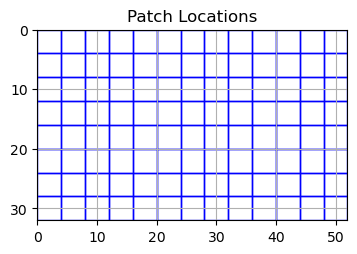

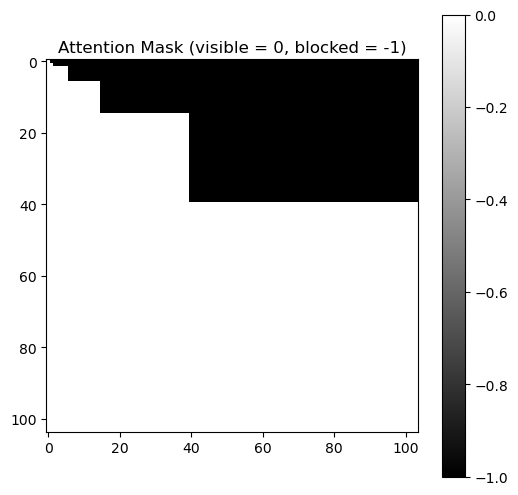

In [4]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from collections import defaultdict
import numpy as np

def get_spiral_metadata(start_size=32, golden_ratio=(5 ** 0.5 - 1) / 2, max_steps=20):
    canvas_size = start_size + int(round(start_size * golden_ratio))
    spiral_metadata = [(0, 0, start_size, start_size)]

    x, y = 0, 0
    w, h = start_size, start_size
    direction = 0

    current_side = start_size
    previous_side = current_side
    next_side = int(start_size * golden_ratio) + 1

    for _ in range(max_steps):
        if next_side <= 1:
            break

        if direction % 4 == 0:  # right
            new_x = x + w
            new_y = y
        elif direction % 4 == 1:  # down
            new_x = x + w - next_side
            new_y = y + h
        elif direction % 4 == 2:  # left
            new_x = x - next_side
            new_y = y + h - next_side
        else:  # up
            new_x = x
            new_y = y - next_side

        if 0 <= new_x < canvas_size and 0 <= new_y < start_size:
            x_clip = min(next_side, canvas_size - new_x)
            y_clip = min(next_side, start_size - new_y)
            if x_clip > 0 and y_clip > 0:
                spiral_metadata.append((new_x, new_y, x_clip, y_clip))

        x, y = new_x, new_y
        w, h = next_side, next_side
        previous_side = current_side
        current_side = next_side
        direction += 1
        next_side = previous_side - current_side

    return (start_size, canvas_size), spiral_metadata
canvas, spiral_metadata = get_spiral_metadata()
print(f"Canvas Size: {canvas}, Spiral Metadata: {spiral_metadata}")

class SpiralPatchEmbed(nn.Module):
    def __init__(self, patch_size, embed_dim, subimage_metadata, in_chans=3):
        super().__init__()
        self.patch_size = patch_size
        self.subimage_metadata = subimage_metadata
        self.in_chans = in_chans
        self.proj = nn.Sequential(
            nn.Flatten(start_dim=2),
            nn.Linear(patch_size * patch_size * in_chans, embed_dim)
        )

    def forward(self, x, return_coords=False):
        B, C, H, W = x.shape
        p = self.patch_size
        patches_all = []
        patch_coords = []
        patch_to_subimage = []

        for subimage_index, (x0, y0, w, h) in enumerate(self.subimage_metadata):
            x1 = min(x0 + w, W)
            y1 = min(y0 + h, H)

            for yy in range(y0, y1 - p + 1, p):
                for xx in range(x0, x1 - p + 1, p):
                    patch = x[:, :, yy:yy + p, xx:xx + p]
                    patches_all.append(patch)
                    patch_coords.append((yy, xx))
                    patch_to_subimage.append(subimage_index)

        patches = torch.stack(patches_all, dim=1)
        patches = patches.reshape(B, -1, C * p * p)
        out = self.proj(patches)

        N = len(patch_to_subimage)
        attn_mask = torch.full((N, N), float('-1'), device=x.device)
        subimage_to_indices = defaultdict(list)
        for idx, sid in enumerate(patch_to_subimage):
            subimage_to_indices[sid].append(idx)
        print(subimage_to_indices)
        sorted_sids = sorted(subimage_to_indices.keys())
        print(sorted_sids)
        # fill attention mask such that: group i attends to itself and all groups after
        all_indices = []
        for sid in sorted_sids:
            indices = subimage_to_indices[sid]
            indices_tensor = torch.tensor(indices, device=x.device)
            all_indices.append(indices_tensor)

        # Construct cumulative structure
        for i, src_indices in enumerate(all_indices):
            visible_indices = torch.cat(all_indices[i:], dim=0)
            attn_mask[src_indices[:, None], visible_indices[None, :]] = 0
        print(patch_coords)
        if return_coords:
            return out, patch_coords, (H, W), attn_mask, patch_to_subimage
        return out

# Assuming SpiralPatchEmbed is already defined above

# Dummy input
B, C, H, W = 1, 3, 32, 52
x = torch.randn(B, C, H, W)

# Define spiral subimages (e.g., 3 nested ones)
subimage_metadata = spiral_metadata

# Instantiate the embedder
patch_size = 4
embed_dim = 64
embedder = SpiralPatchEmbed(patch_size, embed_dim, subimage_metadata)

# Forward pass
out, patch_coords, (H, W), attn_mask, patch_to_subimage = embedder(x, return_coords=True)

# Show patch coordinates
# Plot patch locations
plt.figure(figsize=(4, 4))
for (yy, xx) in patch_coords:
    rect = plt.Rectangle((xx, yy), patch_size, patch_size, edgecolor='blue', facecolor='none')
    plt.gca().add_patch(rect)
plt.xlim(0, W)
plt.ylim(H, 0)
plt.gca().set_aspect('equal')
plt.title('Patch Locations')
plt.grid(True)
plt.show()

# Visualize attention mask
plt.figure(figsize=(6, 6))
mask_np = attn_mask.cpu().numpy()
plt.imshow(mask_np[::-1,::-1], cmap='gray', vmin=mask_np.min(), vmax=0)
plt.title('Attention Mask (visible = 0, blocked = -1)')
plt.colorbar()
plt.show()


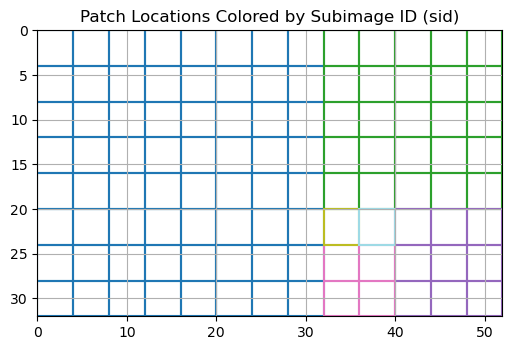

In [19]:
# Plot patch locations with sid-based coloring
plt.figure(figsize=(6, 4))
ax = plt.gca()

# Assign a color for each subimage group (sid)
num_sids = max(patch_to_subimage) + 1
cmap = plt.get_cmap('tab20', num_sids)

for (yy, xx), sid in zip(patch_coords, patch_to_subimage):
    rect = plt.Rectangle((xx, yy), patch_size, patch_size, edgecolor=cmap(sid), facecolor='none', linewidth=1.5)
    ax.add_patch(rect)

plt.xlim(0, W)
plt.ylim(H, 0)
plt.gca().set_aspect('equal')
plt.title('Patch Locations Colored by Subimage ID (sid)')
plt.grid(True)
plt.show()